In [3]:
from WF4Py import waveforms as WF;
from WF4Py import WFutils as utils;

import numpy as np
from astropy.cosmology import Planck18

import pycbc.conversions as cvs;
import pycbc.waveform as pycbc_wf;
import pycbc.types as pycbc_tps;

import time
import sys
import os

import matplotlib.pyplot as pp
from matplotlib import gridspec
from matplotlib import rc
rc('text', usetex=False)


ourcodenameString = 'WF4Py'


/workspace/minconda3/envs/preload/lib/python3.9/site-packages/pykerr/qnm.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [4]:
events = dict(
    mass1 = 33,
    mass2 = 12,
    spin1z = 0.8,
    spin2z = 0.57,
    distance = 0.137,
    inclination = -np.pi/3,
    coa_phase = 0,

    f_lower = 5,
    delta_f = 1.16,
    f_final = 2048,
)

tmpWF = WF.IMRPhenomXAS()
fcut = tmpWF.fcut(**events|{"Mc": np.array([cvs.mchirp_from_mass1_mass2(events['mass1'],events['mass2'])]), "eta": np.array([cvs.eta_from_mass1_mass2(events['mass1'],events['mass2'])])})
fminarr = np.full(fcut.shape, events["f_lower"])
delta_f = events["delta_f"]
fgrids = np.arange(fminarr, fcut, delta_f)
fgrids = fgrids.reshape(-1, 1)

hp1, hc1 = pycbc_wf.get_fd_waveform_sequence(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    sample_points = pycbc_tps.array.Array(fgrids[:,0]),
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['distance']
                                                    )

# hp1 = np.array(hp1).reshape(-1, 1)
# hc1 = np.array(hp2).reshape(-1, 1)

/tmp/ipykernel_3637090/4273745671.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  fgrids = np.arange(fminarr, fcut, delta_f)


In [5]:
import pycbc.types as tps;

def get_dchi_modified_IMRPhenomXAS(**kwargs) :
    # // IMPORTANT CHECK: verify that inclination_azimuth is the longitude of ascending nodes

    mass1 = kwargs["mass1"]
    mass2 = kwargs["mass2"]
    chi1z = kwargs["spin1z"]
    chi2z = kwargs["spin2z"]
    dL = kwargs["distance"]

    phi0 = kwargs["coa_phase"]
    # kwargs["long_asc_nodes"]
    # kwargs["mean_per_ano"]

    events = dict(
        Mc =  np.array([cvs.mchirp_from_mass1_mass2(mass1, mass2)]),
        eta = np.array([cvs.eta_from_mass1_mass2(mass1, mass2)   ]),
        chi1z = np.array([ chi1z ]),
        chi2z = np.array([ chi2z ]),
        dL    = np.array([ dL/1000. ])
    )

    print(events)

    if "dchi0" in kwargs:
        events["dchi0"] = kwargs["dchi0"]
    elif "dchi1" in kwargs:
        events["dchi1"] = kwargs["dchi1"]
    elif "dchi2" in kwargs:
        events["dchi2"] = kwargs["dchi2"]
    elif "dchi3" in kwargs:
        events["dchi3"] = kwargs["dchi3"]
    elif "dchi4" in kwargs:
        events["dchi4"] = kwargs["dchi4"]
    elif "dchi5L" in kwargs:
        events["dchi5L"] = kwargs["dchi5L"]
    elif "dchi5" in kwargs:
        events["dchi5"] = kwargs["dchi5"]
    elif "dchi6" in kwargs:
        events["dchi6"] = kwargs["dchi6"]
    elif "dchi6L" in kwargs:
        events["dchi6L"] = kwargs["dchi6L"]
    elif "dchi7" in kwargs:
        events["dchi7"] = kwargs["dchi7"]
    elif "dchi8" in kwargs:
        events["dchi8"] = kwargs["dchi8"]
    elif "dchi8L" in kwargs:
        events["dchi8L"] = kwargs["dchi8L"]
    else:
        pass

    tmpWF = WF.IMRPhenomXAS(InsPhaseVersion=104, IntPhaseVersion=105, IntAmpVersion=104)

    fcut = np.array([kwargs["f_final"]]) if "f_final" in kwargs else tmpWF.fcut(**events)
    # fcut = tmpWF.fcut(**events)
    fminarr = np.full(fcut.shape, kwargs["f_lower"])
    delta_f = kwargs["delta_f"]
    fgrids = np.arange(fminarr, fcut, delta_f)
    fgrids = fgrids.reshape(-1, 1)

    print(fgrids)

    xas_ampl = tmpWF.Ampl(fgrids, **events) + 2*phi0
    xas_phase22 = tmpWF.Phi(fgrids, **events)

    iota = kwargs["inclination"]

        
    Y_NORM = 2. * np.sqrt(5./(64.*np.pi))
    
    hp, hc = utils.Add_Higher_Modes(Ampl={"22": xas_ampl}, Phi={"22": xas_phase22}, iota=iota)
    # hp, hc = utils.Add_Higher_Modes(Ampl={"22": xas_ampl, "2-2": xas_ampl}, Phi={"22": xas_phase22, "2-2": -xas_phase22}, iota=iota)
    return tps.FrequencySeries(np.conj(hp.reshape(1, -1)[0])/Y_NORM, delta_f=delta_f), tps.FrequencySeries(-np.conj(hc.reshape(1, -1)[0])/Y_NORM, delta_f=delta_f)


events = dict(
    mass1 = 33,
    mass2 = 12,
    spin1z = 0.8,
    spin2z = 0.57,
    distance = 0.137,
    inclination = -np.pi/3,
    coa_phase = 0,

    f_lower = 5,
    delta_f = 1.16,
    f_final = 2048,
)
hp2, hc2 = get_dchi_modified_IMRPhenomXAS(**events)

/tmp/ipykernel_3637090/4207853657.py:59: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  fgrids = np.arange(fminarr, fcut, delta_f)


{'Mc': array([16.90342102]), 'eta': array([0.19555556]), 'chi1z': array([0.8]), 'chi2z': array([0.57]), 'dL': array([0.000137])}
[[   5.  ]
 [   6.16]
 [   7.32]
 ...
 [2045.44]
 [2046.6 ]
 [2047.76]]


KeyError: 'f_lower'

In [ ]:
def get_dchi_modified_IMRPhenomXAS(**kwargs) :
    # // IMPORTANT CHECK: verify that inclination_azimuth is the longitude of ascending nodes

    mass1 = kwargs["mass1"]
    mass2 = kwargs["mass2"]
    chi1z = kwargs["spin1z"]
    chi2z = kwargs["spin2z"]
    dL = kwargs["distance"]

    phi0 = kwargs["coa_phase"]
    # kwargs["long_asc_nodes"]
    # kwargs["mean_per_ano"]

    events = dict(
        Mc =  np.array([cvs.mchirp_from_mass1_mass2(mass1, mass2)]),
        eta = np.array([cvs.eta_from_mass1_mass2(mass1, mass2)   ]),
        chi1z = np.array([ chi1z ]),
        chi2z = np.array([ chi2z ]),
        dL    = np.array([ dL/1000. ])
    )

    print(events)

    if "dchi0" in kwargs:
        events["dchi0"] = kwargs["dchi0"]
    elif "dchi1" in kwargs:
        events["dchi1"] = kwargs["dchi1"]
    elif "dchi2" in kwargs:
        events["dchi2"] = kwargs["dchi2"]
    elif "dchi3" in kwargs:
        events["dchi3"] = kwargs["dchi3"]
    elif "dchi4" in kwargs:
        events["dchi4"] = kwargs["dchi4"]
    elif "dchi5L" in kwargs:
        events["dchi5L"] = kwargs["dchi5L"]
    elif "dchi5" in kwargs:
        events["dchi5"] = kwargs["dchi5"]
    elif "dchi6" in kwargs:
        events["dchi6"] = kwargs["dchi6"]
    elif "dchi6L" in kwargs:
        events["dchi6L"] = kwargs["dchi6L"]
    elif "dchi7" in kwargs:
        events["dchi7"] = kwargs["dchi7"]
    elif "dchi8" in kwargs:
        events["dchi8"] = kwargs["dchi8"]
    elif "dchi8L" in kwargs:
        events["dchi8L"] = kwargs["dchi8L"]
    else:
        pass

    tmpWF = WF.IMRPhenomXAS(InsPhaseVersion=104, IntPhaseVersion=105, IntAmpVersion=104)

    fcut = np.array([kwargs["f_final"]]) if "f_final" in kwargs else tmpWF.fcut(**events)
    # fcut = tmpWF.fcut(**events)
    fminarr = np.full(fcut.shape, kwargs["f_lower"])
    delta_f = kwargs["delta_f"]
    fgrids = np.arange(fminarr, fcut, delta_f)
    fgrids = fgrids.reshape(-1, 1)

    xas_ampl = tmpWF.Ampl(fgrids, **events) + 2*phi0
    xas_phase = tmpWF.Phi(fgrids, **events)

    print(f"xas_phase: {xas_phase[:10]}")

    def htilde22(phase, ampl) :
        return ampl * np.exp(-1j*phase)

    iota = kwargs["inclination"]

    def hphc(phase, ampl, iota) :
        cfac = np.cos(iota)
        Ylmfactor = 2.0 * np.sqrt(5.0 / (64.0 * np.pi)) * np.exp(-1j * 2 * (np.pi/2))
        pfac = 0.5 * (1. + cfac*cfac)
        hp = htilde22(phase, ampl)
        hc = -1j * cfac * hp * Ylmfactor
        hp *= pfac*Ylmfactor

        return hp, hc
    
    Y_NORM = 2. * np.sqrt(5./(64.*np.pi))
    
    hp, hc = hphc(xas_phase, xas_ampl, iota)

    return -np.conj(hp.reshape(1, -1)[0])/Y_NORM, np.conj(hc.reshape(1, -1)[0])/Y_NORM

hp3, hc3 = get_dchi_modified_IMRPhenomXAS(**events)

{'Mc': array([16.90342102]), 'eta': array([0.19555556]), 'chi1z': array([0.8]), 'chi2z': array([0.57]), 'dL': array([0.000137])}


/tmp/ipykernel_1200578/3977705062.py:57: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  fgrids = np.arange(fminarr, fcut, delta_f)


(1762, 1), (1762, 1)
xas_phase: [[   3.92699082]
 [ 467.26984913]
 [ 746.94602259]
 [ 930.15716051]
 [1057.44791732]
 [1149.89867367]
 [1219.41442302]
 [1273.16134161]
 [1315.67788673]
 [1349.95997054]]


In [ ]:
2. * np.sqrt(5./(64.*np.pi))

0.31539156525252005

In [ ]:
pp.plot(np.real(hp1.data), label="lalsuite")
pp.plot(np.real(hp2), label="WF4Py")
pp.plot(np.real(hp3), label="lalsuite, replication")
pp.legend()

# 12

NameError: name 'pp' is not defined

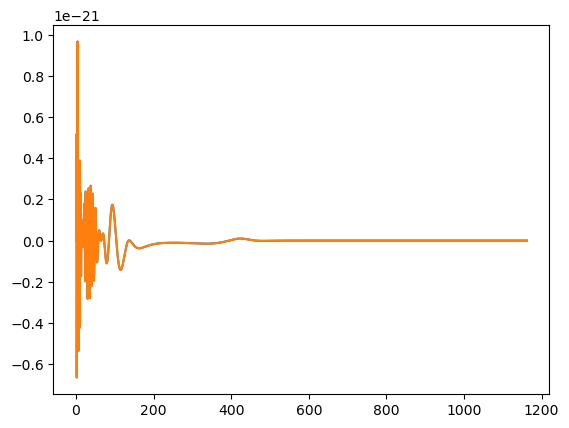

In [ ]:
pp.plot(np.real(hp1.data) - np.real(hp2)[:1163])
pp.plot(np.real(hp1.data) - np.real(hp3)[:1163])

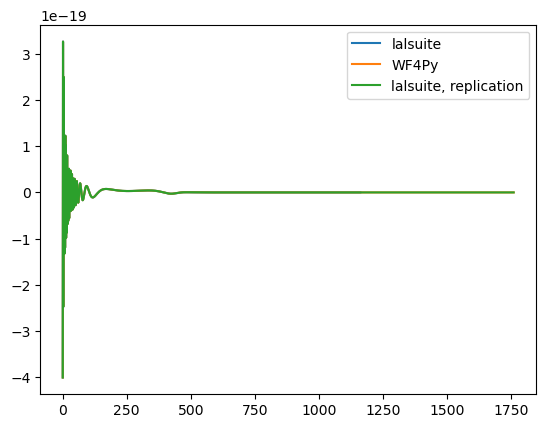

In [ ]:
pp.plot(np.imag(hp1.data), label="lalsuite")
pp.plot(np.imag(hp2), label="WF4Py")
pp.plot(np.imag(hp3), label="lalsuite, replication")
pp.legend()

# 13

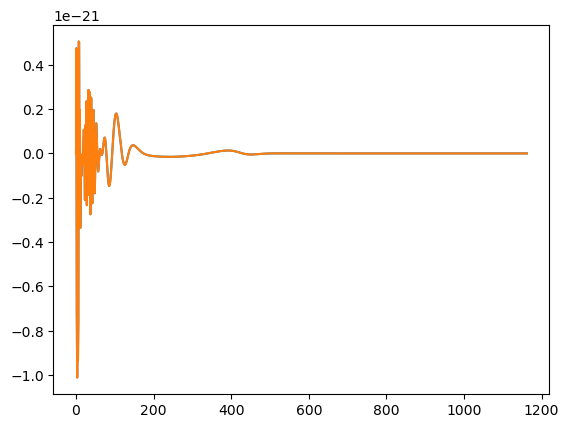

In [ ]:
pp.plot((np.imag(hp1.data)) - np.imag(hp2)[:1163])
pp.plot((np.imag(hp1.data)) - np.imag(hp3)[:1163])

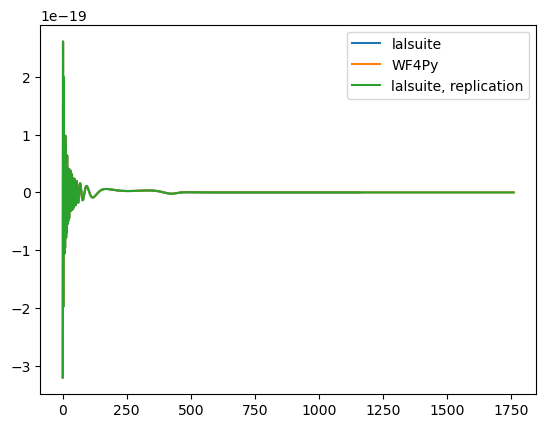

In [ ]:
pp.plot(np.real(hc1.data), label="lalsuite")
pp.plot(np.real(hc2), label="WF4Py")
pp.plot(np.real(hc3), label="lalsuite, replication")
pp.legend()

# 13

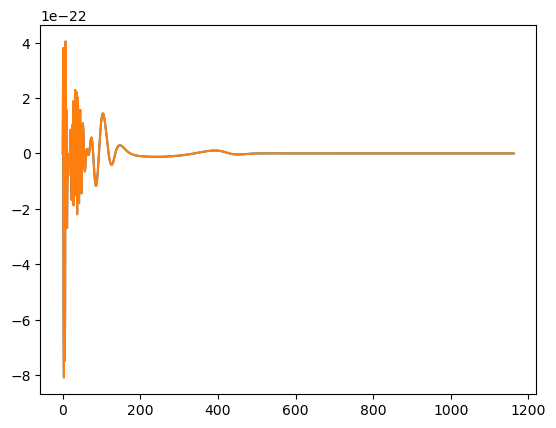

In [ ]:
pp.plot(np.real(hc1.data)-np.real(hc2)[:1163])
pp.plot(np.real(hc1.data)-np.real(hc3)[:1163])

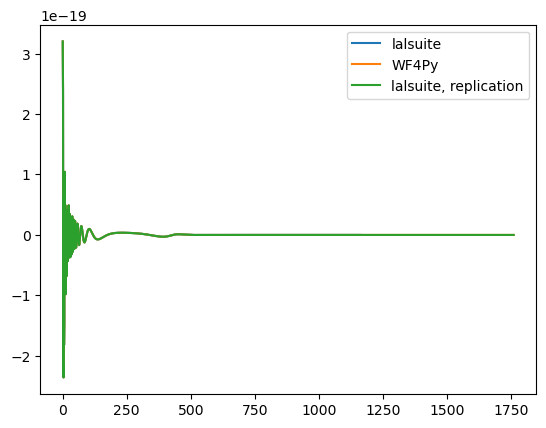

In [ ]:
pp.plot(np.imag(hc1.data), label="lalsuite")
pp.plot(np.imag(hc2), label="WF4Py")
pp.plot(np.imag(hc3), label="lalsuite, replication")
pp.legend()

# 12

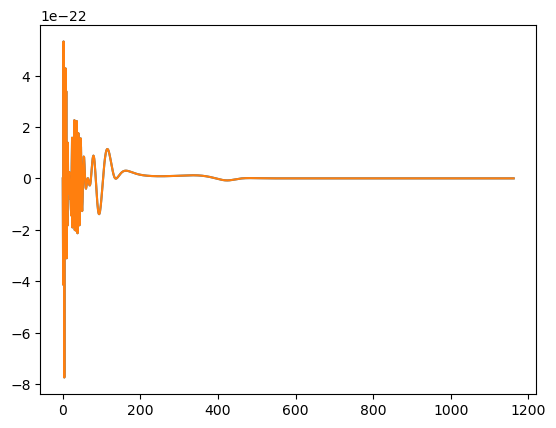

In [ ]:
pp.plot(np.imag(hc1.data)-np.imag(hc2)[:1163])
pp.plot(np.imag(hc1.data)-np.imag(hc3)[:1163])